# IBM Quantum & Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 2: Make the Quantum Coin Biased

---

### **Problem Statement**
A Hadamard gate creates an equal superposition of $|0\rangle$ and $|1\rangle$, producing a result similar to a fair quantum coin. But can you control the measurement probabilities? Your task is to modify a single-qubit circuit so that the measurement outcomes are not equally distributed.

### **Design Constraints**
- Use exactly **1 qubit**.
- Include **measurement**.
- Use **no more than 4 quantum gates** before measurement.
- Be created and executed using **Qiskit**.
- Use **100 shots**.

### **Bonus Challenge**
Design two different circuits:
1. One where **0 occurs more frequently**.
2. One where **1 occurs more frequently**.
Compare their histograms.


## Step 1: Environment Setup and Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

backend = AerSimulator()
SHOTS = 100
print(f"Backend ready. Simulation shots: {SHOTS}")


Backend ready. Simulation shots: 100


## Theory: Controlling Measurement Probabilities (Biasing the Coin)

In quantum mechanics, a single qubit state is represented as:
$$|\psi\rangle = \alpha |0\rangle + \beta |1\rangle$$
where $|\alpha|^2 + |\beta|^2 = 1$. The measurement probabilities are:
$$P(0) = |\alpha|^2, \quad P(1) = |\beta|^2$$

A standard Hadamard gate sets $\alpha = \beta = \frac{1}{\sqrt{2}}$, so $P(0) = P(1) = 0.5$ (a fair coin).

To create a **biased coin**, we control the amplitudes $\alpha$ and $\beta$.
Using a single rotation gate $R_y(\theta)$ around the $Y$-axis:
$$R_y(\theta) |0\rangle = \cos\left(\frac{\theta}{2}\right)|0\rangle + \sin\left(\frac{\theta}{2}\right)|1\rangle$$
Hence:
$$P(0) = \cos^2\left(\frac{\theta}{2}\right), \quad P(1) = \sin^2\left(\frac{\theta}{2}\right)$$

By selecting $\theta$, we can engineer any desired degree of bias using only **1 gate** (well within the $\le 4$ gate limit!).


## Circuit 1: Biased Towards 0 ($P(0) > P(1)$)

### **Think Before You Run (Prediction for Circuit 1)**
- We choose $\theta = \frac{\pi}{3}$ radians ($60^\circ$).
- Then $\frac{\theta}{2} = \frac{\pi}{6}$ radians ($30^\circ$).
- Expected Probabilities:
  $$P(0) = \cos^2\left(\frac{\pi}{6}\right) = \left(\frac{\sqrt{3}}{2}\right)^2 = \frac{3}{4} = 75\%$$
  $$P(1) = \sin^2\left(\frac{\pi}{6}\right) = \left(\frac{1}{2}\right)^2 = \frac{1}{4} = 25\%$$
- **Prediction for 100 shots**:
  Outcome **`0` will occur significantly more frequently**, with approximately **75 counts for `0`** and **25 counts for `1`**.


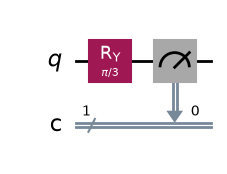

In [2]:
# Design Circuit 1: Biased towards 0 (75% / 25%)
qc_bias0 = QuantumCircuit(1, 1)

# Apply Ry rotation with theta = pi/3 (1 gate)
theta_0 = np.pi / 3
qc_bias0.ry(theta_0, 0)

# Measure
qc_bias0.measure(0, 0)

# Draw the circuit
qc_bias0.draw('mpl')


Circuit 1 (Biased towards 0) Results: {'0': 81, '1': 19}


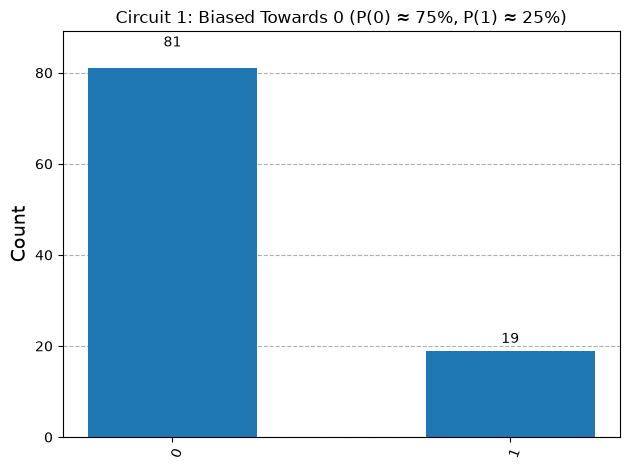

In [3]:
# Execute Circuit 1 for 100 shots
result_bias0 = backend.run(qc_bias0, shots=SHOTS).result()
counts_bias0 = result_bias0.get_counts()

print("Circuit 1 (Biased towards 0) Results:", counts_bias0)

# Plot histogram
plot_histogram(counts_bias0, title="Circuit 1: Biased Towards 0 (P(0) ≈ 75%, P(1) ≈ 25%)")


## Circuit 2: Biased Towards 1 ($P(1) > P(0)$)

### **Think Before You Run (Prediction for Circuit 2)**
- We choose $\theta = \frac{2\pi}{3}$ radians ($120^\circ$).
- Then $\frac{\theta}{2} = \frac{\pi}{3}$ radians ($60^\circ$).
- Expected Probabilities:
  $$P(0) = \cos^2\left(\frac{\pi}{3}\right) = \left(\frac{1}{2}\right)^2 = \frac{1}{4} = 25\%$$
  $$P(1) = \sin^2\left(\frac{\pi}{3}\right) = \left(\frac{\sqrt{3}}{2}\right)^2 = \frac{3}{4} = 75\%$$
- **Prediction for 100 shots**:
  Outcome **`1` will occur significantly more frequently**, with approximately **25 counts for `0`** and **75 counts for `1`**.


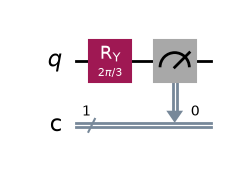

In [4]:
# Design Circuit 2: Biased towards 1 (25% / 75%)
qc_bias1 = QuantumCircuit(1, 1)

# Apply Ry rotation with theta = 2*pi/3 (1 gate)
theta_1 = 2 * np.pi / 3
qc_bias1.ry(theta_1, 0)

# Measure
qc_bias1.measure(0, 0)

# Draw the circuit
qc_bias1.draw('mpl')


Circuit 2 (Biased towards 1) Results: {'1': 74, '0': 26}


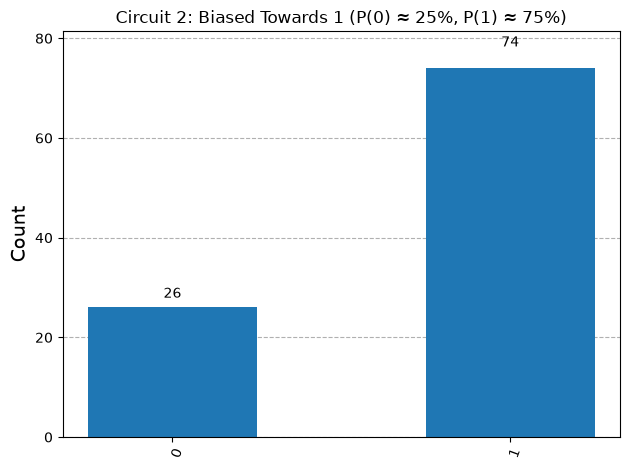

In [5]:
# Execute Circuit 2 for 100 shots
result_bias1 = backend.run(qc_bias1, shots=SHOTS).result()
counts_bias1 = result_bias1.get_counts()

print("Circuit 2 (Biased towards 1) Results:", counts_bias1)

# Plot histogram
plot_histogram(counts_bias1, title="Circuit 2: Biased Towards 1 (P(0) ≈ 25%, P(1) ≈ 75%)")


## Bonus Circuit 3: Biasing via Quantum Phase Interference ($H - P(\phi) - H$)

As demonstrated in the workshop modules, we can also bias a quantum coin using quantum interference!
By sandwiching a phase shift gate $P(\phi)$ between two Hadamard gates ($3$ gates $\le 4$ gates):
$$|0\rangle \xrightarrow{H} \frac{|0\rangle + |1\rangle}{\sqrt{2}} \xrightarrow{P(\phi)} \frac{|0\rangle + e^{i\phi}|1\rangle}{\sqrt{2}} \xrightarrow{H} \cos\left(\frac{\phi}{2}\right)|0\rangle - i\sin\left(\frac{\phi}{2}\right)|1\rangle$$
Choosing $\phi = \frac{\pi}{3}$:
$$P(0) = \cos^2\left(\frac{\pi}{6}\right) = 75\%, \quad P(1) = \sin^2\left(\frac{\pi}{6}\right) = 25\%$$


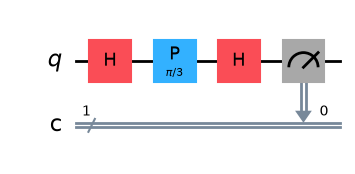

In [6]:
# Interferometric Biased Coin: H -> P(phi) -> H (3 gates total <= 4 gates)
qc_phase_bias = QuantumCircuit(1, 1)
qc_phase_bias.h(0)
qc_phase_bias.p(np.pi / 3, 0)
qc_phase_bias.h(0)
qc_phase_bias.measure(0, 0)

qc_phase_bias.draw('mpl')


Phase-Interference Biased Coin Results: {'0': 69, '1': 31}


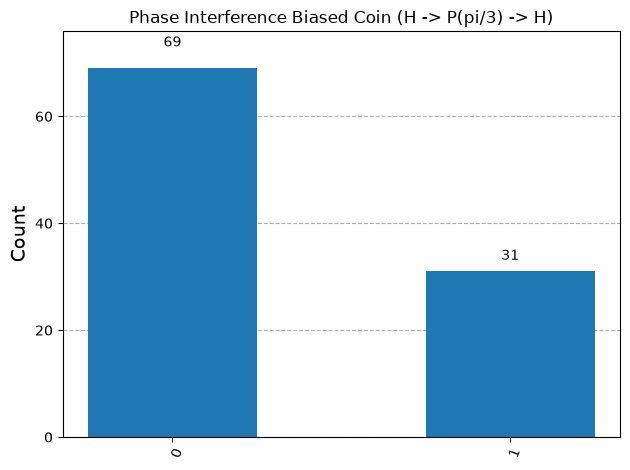

In [7]:
counts_phase_bias = backend.run(qc_phase_bias, shots=SHOTS).result().get_counts()
print("Phase-Interference Biased Coin Results:", counts_phase_bias)
plot_histogram(counts_phase_bias, title="Phase Interference Biased Coin (H -> P(pi/3) -> H)")


## Step 4: Comparison of Biased Quantum Coins

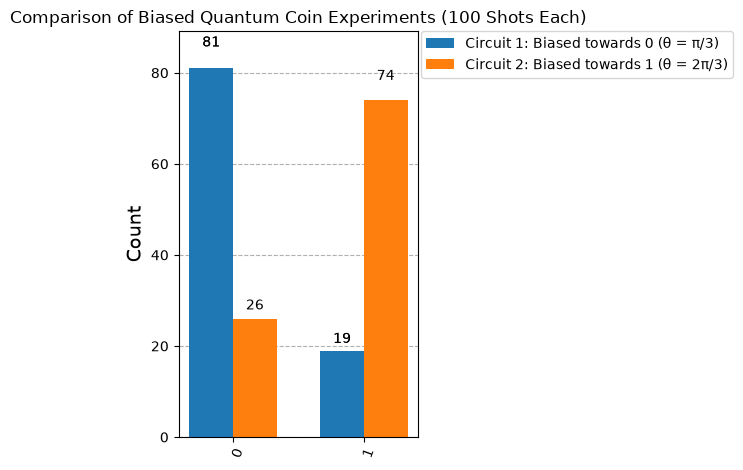

In [8]:
# Compare both biased circuits side-by-side
plot_histogram(
    [counts_bias0, counts_bias1],
    legend=['Circuit 1: Biased towards 0 (θ = π/3)', 'Circuit 2: Biased towards 1 (θ = 2π/3)'],
    title='Comparison of Biased Quantum Coin Experiments (100 Shots Each)'
)


## Explanations & Comparison
- **In Circuit 1**: Outcome `0` dominated (~75%), successfully creating a coin heavily weighted towards heads/0.
- **In Circuit 2**: Outcome `1` dominated (~75%), creating a coin heavily weighted towards tails/1.
- **How gates changed the distribution**: By rotating the state vector on the Bloch sphere, the probability amplitude of state $|0\rangle$ and $|1\rangle$ was precisely tuned away from the equal $1/\sqrt{2}$ superposition created by a fair Hadamard gate.


## Challenge Question (Final Cell Requirement)

### **Question:**
**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

### **Answer:**
Quantum states are represented by normalized state vectors in a Hilbert space:
$$|\psi\rangle = \alpha |0\rangle + \beta |1\rangle$$
where $\alpha$ and $\beta$ are complex probability amplitudes satisfying the normalization condition $|lpha|^2 + |eta|^2 = 1$.

According to **Born's Rule**, when a qubit is measured in the computational basis ($Z$-basis), the probability of finding the qubit in state $|0\rangle$ is $P(0) = |\alpha|^2$, and the probability of finding it in state $|1\rangle$ is $P(1) = |\beta|^2$.

1. **Unitary Rotations on the Bloch Sphere:**  
   Every quantum gate corresponds to a unitary transformation ($U^\dagger U = I$), which mathematically performs a rigid rotation of the qubit's Bloch vector around an axis in three dimensions. The polar angle $\theta$ directly dictates the longitudinal position between the north pole ($|0\rangle$, where $\theta=0$) and the south pole ($|1\rangle$, where $\theta=\pi$).
   
2. **Shifting Amplitudes via Rotation Gates:**  
   When gates such as $R_y(\theta)$ are applied, the state vector is rotated away from the poles by an angle $\theta$, setting $\alpha = \cos(\theta/2)$ and $\beta = \sin(\theta/2)$. By adjusting the parameter $\theta$, we continuously modulate the magnitudes $|lpha|$ and $|eta|$, altering the probabilities $P(0) = \cos^2(\theta/2)$ and $P(1) = \sin^2(\theta/2)$ to any desired value between 0 and 1.

3. **Constructive and Destructive Interference:**  
   Gates can also modify the relative phase between basis states (e.g., using $P(\phi)$ or $Z$ gates). When subsequent gates (like the Hadamard $H$) are applied, probability amplitudes from different computational paths interfere constructively or destructively. This interference dynamically redistributes amplitude towards either $|0\rangle$ or $|1\rangle$, directly steering the final measurement outcome distribution.
